In [51]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [52]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [53]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [54]:
latitude = [30,60]
mask = '1'

In [55]:
if mask == '1':
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_land_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_land_daily_1_1990-2050_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_land_1_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_land_daily_1_2020-2050_30-60N_precip_count_sum.nc')['dry']
    cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_land_1_30-60N_precip_count_sum.nc')['PRECT']
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/test_imerg_land_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
    ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
    icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
    icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))
else:
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_land_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_land_concat_1990-2019_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_land_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_land_concat_2020-2024_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_land_'+mask+'_30-60N_precip_count_sum.nc')['PRECT']
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/correct_imerg_land_concat_2014-2023_'+mask+'_30-60N_precip_count_sum.nc')['dry']


In [56]:
print(ifs_on)

<xarray.DataArray 'dry' (time: 184)> Size: 736B
[184 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 1kB 2020-05-01 2020-05-02 ... 2020-10-31


In [57]:
print(ifs_off)

<xarray.DataArray 'dry' (time: 184)> Size: 736B
[184 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 1kB 2020-05-01 2020-05-02 ... 2020-10-31


In [58]:
print(imerg)


<xarray.DataArray 'dry' (time: 4385)> Size: 18kB
[4385 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 35kB 2000-06-01T11:45:00 ... 2023-10-31T11...


## IFS on

In [59]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/land/land_IFS_2.8-FESOM_5_30-60N_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_on = ifs_on / total_cells * 100  # DataArray of length time
weights_ifs_high = np.ones_like(percent_ifs_on) * 100.0 / percent_ifs_on.size

## IFS off

In [60]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/land/land_IFS_2.8-FESOM_5_30-60N_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_off = ifs_off / total_cells * 100  # DataArray of length time


In [61]:
print(ifs_size)

<xarray.DataArray 'tp' (time: 1, value: 4697561)> Size: 38MB
[4697561 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 8B 2020-10-29
    lon      (value) float64 38MB ...
    lat      (value) float64 38MB ...
Dimensions without coordinates: value
Attributes:
    CDI_grid_type:  unstructured


## IFS Cycle3

In [62]:
ifs_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
ifs_cycle3_land = xr.where(ifs_cycle3_size > 0, 1, 0)

total_cells = ifs_cycle3_land.sum()
percent_ifs_cycle3 = ifs_cycle3 / total_cells * 100  # DataArray of length time
weights_ifs_cycle3 = np.ones_like(percent_ifs_cycle3) * 100.0 / percent_ifs_cycle3.size

## IFS Cycle4

In [63]:
ifs_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_cycle4_land = xr.where(ifs_cycle4_size > 0, 1, 0)
total_cells = ifs_cycle4_land.sum()
percent_ifs_cycle4 = ifs_cycle4 / total_cells * 100  # DataArray of length time
weights_ifs_cycle4 = np.ones_like(percent_ifs_cycle4) * 100.0 / percent_ifs_cycle4.size

## ICON Cycle3

In [64]:
icon_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
icon_cycle3_land = xr.where(icon_cycle3_size < 1, 1, 0)
total_cells = icon_cycle3_land.sum()
percent_icon_cycle3 = icon_cycle3 / total_cells * 100  # DataArray of length time
weights_icon_cycle3 = np.ones_like(percent_icon_cycle3) * 100.0 / percent_icon_cycle3.size

## ICON Cycle4

In [65]:
icon_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
icon_cycle4_land = xr.where(icon_cycle4_size < 1, 1, 0)
total_cells = icon_cycle4_land.sum()
percent_icon_cycle4 = icon_cycle4 / total_cells * 100  # DataArray of length time
weights_icon_cycle4 = np.ones_like(percent_icon_cycle4) * 100.0 / percent_icon_cycle4.size

## CESM2

In [66]:
cesm2_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
cesm2_size = cesm2_size[0,:,:]
indexer = ((cesm2_size.lat>=latitude[0]) & (cesm2_size.lat<=latitude[1]))
cesm2_size = cesm2_size.where(indexer,drop=True)
# 5) Compute percentage of grid cells for each time
cesm2_land = xr.where(cesm2_size > 0, 1, 0)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(cesm2_size['lat'])),
    dims=['lat'],
    coords={'lat': cesm2_size['lat']}
)
total_cells = cesm2_land.weighted(lat_weights).sum()
percent_cesm2 = cesm2 / total_cells * 100  # DataArray indexed by time
weights_cesm2 = np.ones_like(percent_cesm2) * 100.0 / percent_cesm2.size

## IMERG

In [67]:
imerg_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
# 5) Compute percentage of grid cells for each time
imerg_land = xr.where(imerg_size < 100, 1, 0)
lat_weights = np.cos(np.deg2rad(imerg_size['lat']))

total_cells = imerg_land.weighted(lat_weights).sum()
percent_imerg = imerg / total_cells * 100  # DataArray indexed by time
weights_imerg = np.ones_like(percent_imerg) * 100.0 / percent_imerg.size

In [68]:
print(np.median(percent_imerg))


26.291921948945387


In [69]:
print(np.median(percent_cesm2))

30.753692405668584


In [70]:
pct_above_13 = float((percent_cesm2 > 13).sum() / percent_cesm2.size * 100)
print(f'{pct_above_13:.2f}%')

100.00%


In [71]:
print(np.median(percent_ifs_off))

25.524756357607703


In [72]:
print(np.median(percent_ifs_on))

26.763899393749224


In [73]:
print(np.median(percent_icon_cycle4))

25.94525799437328


In [74]:
print(np.median(percent_icon_cycle3))

21.902371394891674


In [75]:
print(np.median(percent_ifs_cycle3))

26.41334025317598


In [76]:
print(np.median(percent_ifs_cycle4))

25.960589644964458


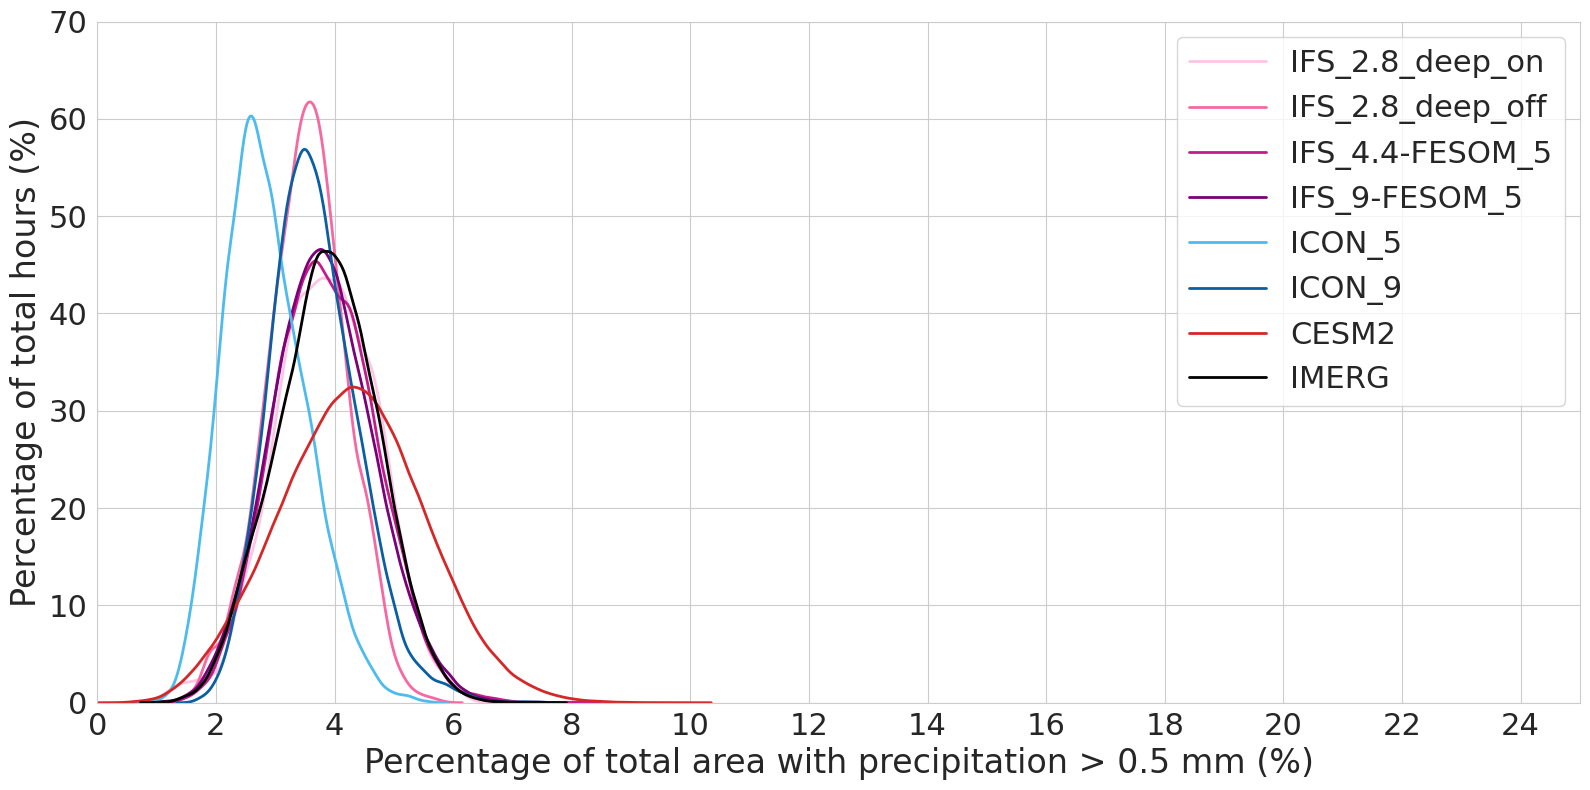

In [49]:
# 1) Common x-range + bin width
if mask == '01':
    xmin, xmax = 0, 35

elif mask == '02':
    xmin, xmax = 0, 25

elif mask == '05':
    xmin, xmax = 0, 25

elif mask == '1':
    xmin, xmax = 10, 50
bin_width  = 1.0
# 2) Your datasets
#datasets = [
#    (percent_ifs_on,    weights,     '#FF8C69', 'IFS_2.8_deep_on'),
#    (percent_ifs_off,   weights,     '#7FFF7F', 'IFS_2.8_deep_off'),
#    (percent_ifs_cycle3,weights,     '#6BB7EC', 'IFS_4.4-FESOM_5'),
#    (percent_ifs_cycle4,weights,     '#FF69B4', 'IFS_9-FESOM_5'),
#    (percent_icon_cycle3,weights,     '#C5A5CF80', 'ICON_5'),
#    (percent_cesm2,     weights_cesm2,'#FFC300','CESM2'),
#    (percent_imerg,     weights,     '#7E57C2', 'IMERG'),
#]


#datasets = [
    # IFS group – improved contrast (warm & distinct)
#    (percent_ifs_on,     weights_ifs_high,    '#D73027', 'IFS_2.8_deep_on'),   # deep red
#    (percent_ifs_off,    weights_ifs_high,    '#FC8D59', 'IFS_2.8_deep_off'),  # coral/orange
#    (percent_ifs_cycle3, weights_ifs_cycle3,  '#91BFDB', 'IFS_4.4-FESOM_5'),   # sky blue
#    (percent_ifs_cycle4, weights_ifs_cycle4,  '#4575B4', 'IFS_9-FESOM_5'),     # strong blue

    # ICON group – cohesive purples
#    (percent_icon_cycle3, weights_icon_cycle3, '#9467BD', 'ICON_5'),           # medium purple
#    (percent_icon_cycle4, weights_icon_cycle4, '#C5B0D5', 'ICON_9'),           # soft lilac

    # CESM2 – distinct highlight (gold)
#    (percent_cesm2,      weights_cesm2,       '#E6AB02', 'CESM2'),

    # IMERG – distinct but not pure black (deep violet)
#    (percent_imerg,      weights_imerg,       'k', 'IMERG'),
#]

datasets = [
    # IFS group – range of magentas (light → dark)
    (percent_ifs_on,     weights_ifs_high,    '#FCC5E4', 'IFS_2.8_deep_on'),   # pale pink-magenta
    (percent_ifs_off,    weights_ifs_high,    '#F768A1', 'IFS_2.8_deep_off'),  # mid magenta
    (percent_ifs_cycle3, weights_ifs_cycle3,  '#C51B8A', 'IFS_4.4-FESOM_5'),   # strong magenta
    (percent_ifs_cycle4, weights_ifs_cycle4,  '#7A0177', 'IFS_9-FESOM_5'),     # deep magenta
    # ICON group – range of blues (light → dark)
    (percent_icon_cycle3, weights_icon_cycle3, '#4DBBEE', 'ICON_5'),           # sky blue
    (percent_icon_cycle4, weights_icon_cycle4, '#0A5FA3', 'ICON_9'),           # deep blue
    # CESM2 – red
    (percent_cesm2,      weights_cesm2,       '#D62728', 'CESM2'),
    # IMERG – black
    (percent_imerg,      weights_imerg,       '#000000', 'IMERG'),
]

plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

# 3) Plot only the KDEs
for data_da, wts_da, color, label in datasets:
    # extract numpy
    x = data_da.values.ravel()
    w = wts_da.values.ravel() if hasattr(wts_da, 'values') else np.asarray(wts_da).ravel()
    # drop NaNs
    #mask_plot = ~np.isnan(x)
    #x, w = x[mask_plot], w[mask_plot]
    #print(label)
    #print(len(x))
    # normalize weights so area under curve = 1
    #w_norm = w 
  
    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=1.0,      # tweak for smoother / sharper
        clip=(xmin, xmax),
        common_norm=False,  # each curve normalizes to its own w_norm
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '1':
    xl = 'Percentage of total area with precipitation > 1 mm (%)'
    ax.set_ylim(0, 18)

plt.xlabel(xl, fontsize=24)
if mask == '1':
    plt.ylabel('Percentage of total days (%)', fontsize=24)
else:
    plt.ylabel('Percentage of total hours (%)', fontsize=24)

plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_all_histo_precip_coverage_'+mask+'_new.pdf', format='pdf',bbox_inches='tight')

plt.show()

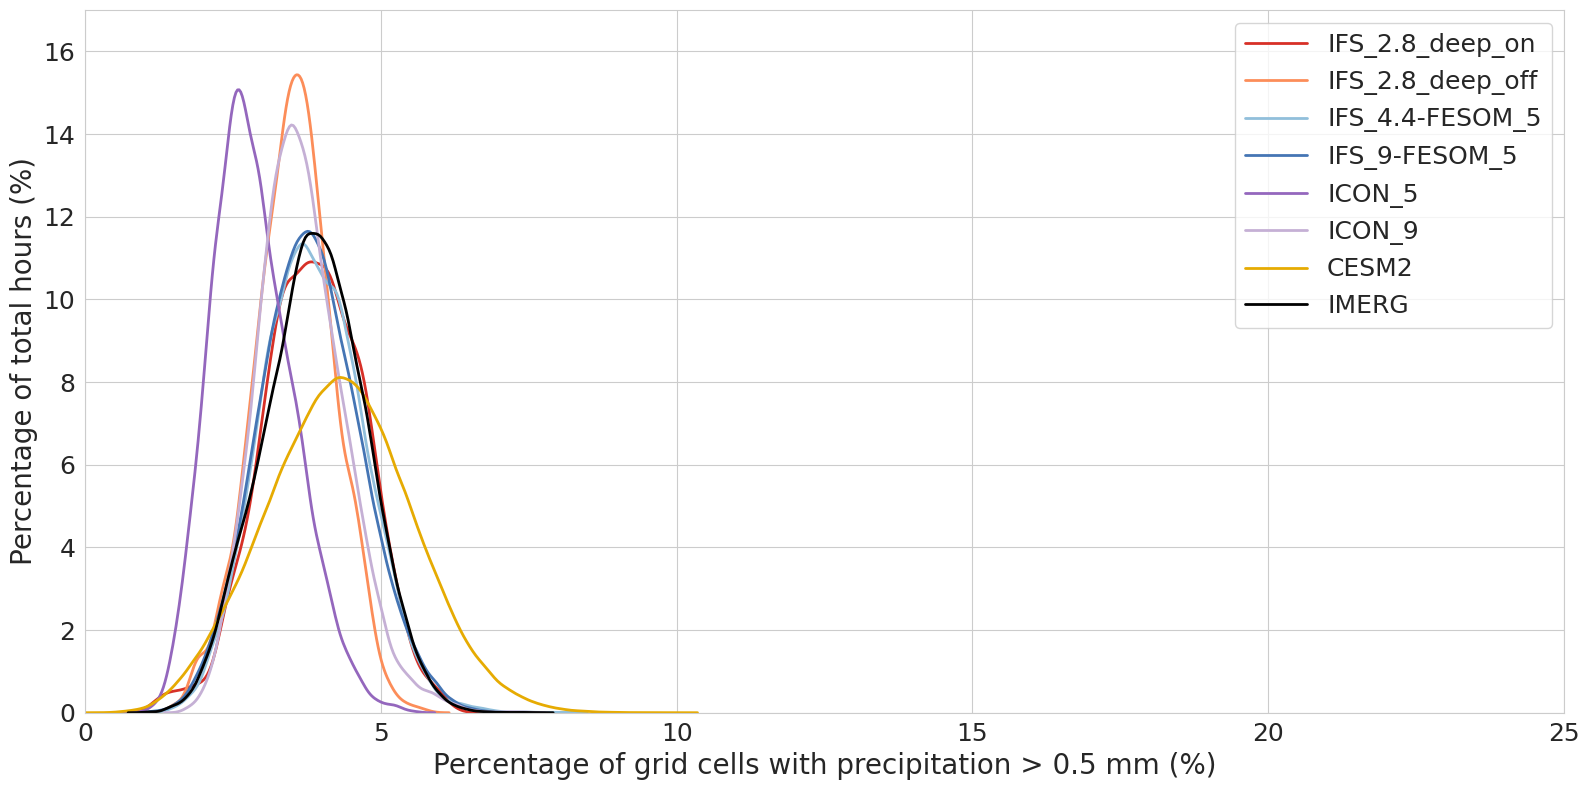

In [50]:
# 1) Common x-range + bin width
if mask == '01':
    xmin, xmax = 0, 35

elif mask == '02':
    xmin, xmax = 0, 25

elif mask == '05':
    xmin, xmax = 0, 25

elif mask == '1':
    xmin, xmax = 0, 60
bin_width  = 0.25




datasets = [
    # IFS group – improved contrast (warm & distinct)
    (percent_ifs_on,         '#D73027', 'IFS_2.8_deep_on'),   # deep red
    (percent_ifs_off,        '#FC8D59', 'IFS_2.8_deep_off'),  # coral/orange
    (percent_ifs_cycle3,  '#91BFDB', 'IFS_4.4-FESOM_5'),   # sky blue
    (percent_ifs_cycle4,   '#4575B4', 'IFS_9-FESOM_5'),     # strong blue

    # ICON group – cohesive purples
    (percent_icon_cycle3,  '#9467BD', 'ICON_5'),           # medium purple
    (percent_icon_cycle4,  '#C5B0D5', 'ICON_9'),           # soft lilac

    # CESM2 – distinct highlight (gold)
    (percent_cesm2,             '#E6AB02', 'CESM2'),

    # IMERG – distinct but not pure black (deep violet)
    (percent_imerg,             'k', 'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=14)

# 3) Plot only the KDEs
for data_da, color, label in datasets:
    # extract numpy
    x = data_da.values.ravel()
    # drop NaNs
    #mask_plot = ~np.isnan(x)
    #x, w = x[mask_plot], w[mask_plot]
    #print(label)
    #print(len(x))
    # normalize weights so area under curve = 1
    #w_norm = w 
  
    sns.kdeplot(
        x=x,
        bw_adjust=1.0,      # tweak for smoother / sharper
        clip=(xmin, xmax),
        common_norm=False,  # each curve normalizes to its own w_norm
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
if mask == '01':
    xl = 'Percentage of grid cells with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 8)
elif mask == '02':
    xl = 'Percentage of grid cells with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 17)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '05':
    xl = 'Percentage of grid cells with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 17)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '1':
    xl = 'Percentage of grid cells with precipitation > 1 mm (%)'
    ax.set_ylim(0, 5)

plt.xlabel(xl, fontsize=20)
if mask == '1':
    plt.ylabel('Percentage of total days (%)', fontsize=20)
else:
    plt.ylabel('Percentage of total hours (%)', fontsize=20)

plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=18)


# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 18},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
#plt.savefig('/home/jwille/images/global_paper/mid_lat_land_all_histo_precip_coverage_'+mask+'_new.pdf', format='pdf',bbox_inches='tight')

plt.show()